In [40]:
import uproot
import os
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import numpy as np
import sys

In [41]:
def normalize(histArray,bins):
    return histArray/sum(histArray)/(bins[1]-bins[0])

def rebin(histArray,n,bins):
    newHist=[]
    newBins=[]
    for binc in range(0,len(bins)-1,n):
       tot=0
       newBins.append(bins[binc])
       for subBin in range(n):
          if (binc+subBin)<(len(bins)-1):
             tot=tot+histArray[binc+subBin]
       newHist.append(tot)
    newBins.append(bins[len(bins)-1])
    return np.array(newHist),newBins

def flipSum(histOne,histTwo):
    newHist=[]
    for binc in range(0,len(histOne)):
        newHist.append(histOne[binc]+histTwo[len(histOne)-1-binc])
    return np.array(newHist)

def plot(hist,bins,dataHist=None,dataBins=None,title=None,figName='standaloneMuonValidation.pdf',xlabel='Standalone Muon $\Delta$E/E',ylabel='Relative Rate',cmsX=-0.9,cmsY=1.45,ylim=None,xlim=None,mclab="mc",datalab="data",cmsoff=0.1):
    plt.figure(figsize=(8, 8))
    if dataHist is not None:
        ax1=plt.subplot(3,1,(1,2))
    else:
        ax1=plt.subplot(1,1,1)    
    databincenters = [(dataBins[i]+dataBins[i+1])/2. for i in range(len(dataBins)-1)]
    bincenters = [(bins[i]+bins[i+1])/2. for i in range(len(bins)-1)]
    plt.fill_between(bincenters,hist,step="mid",label=mclab)
    if dataHist is not None:
        plt.plot(databincenters,dataHist,'ks', label=datalab)
    plt.legend(frameon=False,fontsize=20)
    if title is not None:
        plt.title(title, loc='center',fontsize=20)
    plt.ylabel(ylabel, fontsize = 20)
    if dataHist is not None:
        ratArr = []
        for xbin in range(len(bins)-1):
            if hist[xbin]>0:
                ratArr.append(dataHist[xbin]/hist[xbin])
            else:
                ratArr.append(0)
    plt.text(cmsX, cmsY, 'CMS', fontsize = 16)
    plt.text(cmsX+cmsoff, cmsY, 'Internal', fontsize=12,style='italic')
    if dataHist is not None:
        plt.subplots_adjust(bottom=0)
        ax1.set_xticks([])
    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)
    if dataHist is not None:
        ax2=plt.subplot(313)
        plt.tick_params('x',top=True)
        plt.ylabel('Data/MC',fontsize=16)
        plt.plot(databincenters,ratArr,'ks')
        if xlim is not None:
            plt.plot(xlim,[1,1],'k',linewidth=2,linestyle='dashed')
        plt.subplots_adjust(hspace=0)
        if xlim is not None:
            plt.xlim(xlim)
    plt.xlabel(xlabel,fontsize=20)
    plt.savefig(figName,bbox_inches='tight')
    return 
    

In [42]:
inDir="/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms"
mcFile = uproot.open(str(inDir)+"/highHcal_mc.root")
dataFile = uproot.open(str(inDir)+"/highHcal_data.root")
mcHist=mcFile["demo"]["partialDisappear"]["StandaloneMuondEoverE"].to_numpy()
dataHist=dataFile["demo"]["partialDisappear"]["StandaloneMuondEoverE"].to_numpy()
mcPhiPlusQHist=mcFile["demo"]["partialDisappear"]["StandalonedPhiPosQ"].to_numpy()
mcPhiMinusQHist=mcFile["demo"]["partialDisappear"]["StandalonedPhiNegQ"].to_numpy()
dataPhiPlusQHist=dataFile["demo"]["partialDisappear"]["StandalonedPhiPosQ"].to_numpy()
dataPhiMinusQHist=dataFile["demo"]["partialDisappear"]["StandalonedPhiNegQ"].to_numpy()
mcPhiHist=flipSum(mcPhiPlusQHist[0],mcPhiMinusQHist[0])
mcPhiBins=mcPhiPlusQHist[1]
dataPhiHist=flipSum(dataPhiPlusQHist[0],dataPhiMinusQHist[0])
dataPhiBins=dataPhiPlusQHist[1]
mcChiHist=mcFile["demo"]["partialDisappear"]["standaloneChi2"].to_numpy()
dataChiHist=dataFile["demo"]["partialDisappear"]["standaloneChi2"].to_numpy()

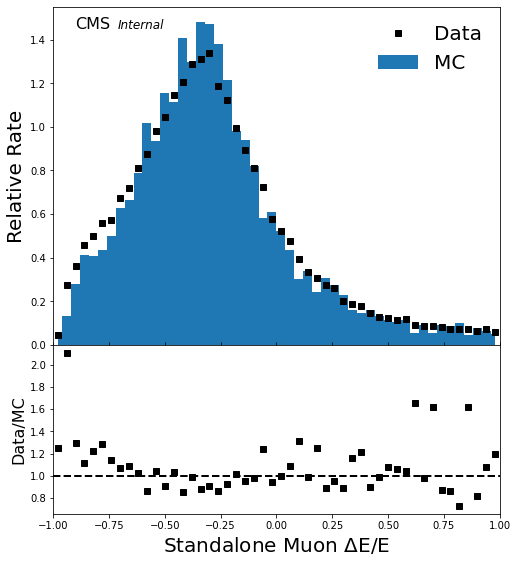

In [43]:
plt.figure(figsize=(8, 8))
ax1=plt.subplot(3,1,(1,2))
rebinMC=rebin(mcHist[0],4,mcHist[1])
normMCHist=normalize(rebinMC[0],rebinMC[1])
rebinData=rebin(dataHist[0],4,dataHist[1])
normDataHist=normalize(rebinData[0],rebinData[1])
bins=rebinMC[1]
bincentres = [(bins[i]+bins[i+1])/2. for i in range(len(bins)-1)]
#bincentres = [bins[i] for i in range(len(bins)-1)]
databins=rebinData[1]
databincentres = [(databins[i]+databins[i+1])/2. for i in range(len(databins)-1)]
plt.fill_between(bincentres,normMCHist,step="mid",label='MC')
#plt.plot(bincentres,normMCHist,color='b',linestyle='-',label='MC',drawstyle="steps")
plt.plot(databincentres,normDataHist,'ks', label='Data')
#plt.plot(databincentres,normDataHist,'ks',linestyle='-', label='Data',drawstyle="steps")
plt.legend(frameon=False,fontsize=20)
#plt.title("High HCAL CR", loc='center',fontsize=20)

plt.ylabel('Relative Rate', fontsize = 20)
#plt.text(0.2, 0.6, 'Data Mean = -0.29,\nData Std. Dev. = 0.37\nMC Mean = -0.28,\nMC Std. Dev. = 0.36', fontsize = 16)
ratArr = []
for xbin in range(len(bins)-1):
    ratArr.append(normDataHist[xbin]/normMCHist[xbin])
cmsX=-0.9
cmsY=1.45
plt.text(cmsX, cmsY, 'CMS', fontsize = 16)
plt.text(cmsX+0.19, cmsY, 'Internal', fontsize=12,style='italic')
plt.subplots_adjust(bottom=0)
ax1.set_xticks([])
plt.xlim([-1,1])
plt.ylim([0,1.55])
ax2=plt.subplot(313)
plt.tick_params('x',top=True)
plt.ylabel('Data/MC',fontsize=16)
plt.plot(databincentres,ratArr,'ks')
plt.plot([-1,1],[1,1],'k',linewidth=2,linestyle='dashed')
plt.subplots_adjust(hspace=0)
plt.xlabel('Standalone Muon $\Delta$E/E',fontsize=20)
plt.xlim([-1,1])
plt.savefig('standaloneMuonValidation.pdf',bbox_inches='tight')
plt.show()

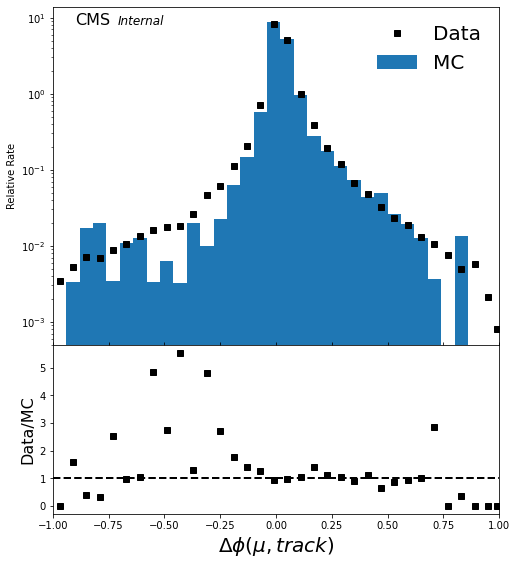

In [44]:
plt.figure(figsize=(8, 8))
rebinMC=rebin(mcPhiHist,3,mcPhiBins)
normMCPhiHist=normalize(rebinMC[0],rebinMC[1])
rebinData=rebin(dataPhiHist,3,dataPhiBins)
normDataHist=normalize(rebinData[0],rebinData[1])
bins=rebinMC[1]
bincentres = [(bins[i]+bins[i+1])/2. for i in range(len(bins)-1)]
databins=rebinData[1]
ax1=plt.subplot(3,1,(1,2))
databincentres = [(databins[i]+databins[i+1])/2. for i in range(len(databins)-1)]
plt.fill_between(bincentres,normMCPhiHist,step="mid",label='MC')
#plt.step(bincentres,normMCPhiHist,where='mid',color='b',linestyle='-',label='MC')
plt.plot(databincentres,normDataHist,'sk', label='Data')
plt.legend(frameon=False,fontsize=20)
plt.ylabel('Relative Rate')
plt.yscale('log')
cmsX=-0.9
cmsY=8
plt.text(cmsX, cmsY, 'CMS', fontsize = 16)
plt.text(cmsX+0.19, cmsY, 'Internal', fontsize=12,style='italic')
plt.subplots_adjust(bottom=0)
ax1.set_xticks([])
plt.xlim([-1,1])
#plt.ylim([0,1.55])
ratArr = []
for xbin in range(len(bins)-1):
    if normMCPhiHist[xbin]>0:
        ratArr.append(normDataHist[xbin]/normMCPhiHist[xbin])
    else:
        ratArr.append(0)
ax2=plt.subplot(313)
plt.tick_params('x',top=True)
plt.ylabel('Data/MC',fontsize=16)
plt.plot(databincentres,ratArr,'ks')
plt.plot([-1,1],[1,1],'k',linewidth=2,linestyle='dashed')
plt.subplots_adjust(hspace=0)
plt.xlabel('$\Delta\phi(\mu,track)$',fontsize=20)
plt.xlim([-1,1])
plt.savefig('standaloneMuonPhiValidation.pdf',bbox_inches='tight')
plt.show()
#plt.text(0.2, 0.6, 'Data Mean = -0.29,\nData Std. Dev. = 0.37\nMC Mean = -0.28,\nMC Std. Dev. = 0.36', fontsize = 16)
#plt.savefig('standaloneMuonValidation.png')


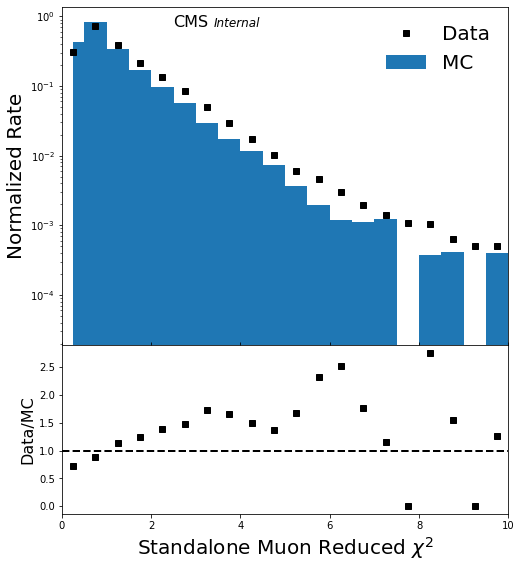

In [45]:
plt.figure(figsize=(8, 8))
#rebinMC=rebin(mcHist[0],3,mcHist[1])
normMCChiHist=normalize(mcChiHist[0],mcChiHist[1])
normDataHist=normalize(dataChiHist[0],dataChiHist[1])
bins=mcChiHist[1]
bincentres = [(bins[i]+bins[i+1])/2. for i in range(len(bins)-1)]
databins=dataChiHist[1]
databincentres = [(databins[i]+databins[i+1])/2. for i in range(len(databins)-1)]
ax1=plt.subplot(3,1,(1,2))
plt.fill_between(bincentres,normMCChiHist,step="mid",label='MC')
plt.step(databincentres,normDataHist,'ks', label='Data')
plt.legend(frameon=False,fontsize=20)
#plt.title("High HCAL CR", loc='center')
plt.xlabel('Standalone Muon Reduced $\chi$^2')
plt.ylabel('Normalized Rate',fontsize=20)
plt.yscale('log')
plt.xlim([0, 10])
cmsX=2.5
cmsY=0.7
plt.text(cmsX, cmsY, 'CMS', fontsize = 16)
plt.text(cmsX+0.9, cmsY, 'Internal', fontsize=12,style='italic')
plt.subplots_adjust(bottom=0)
ax1.set_xticks([])
ratArr = []
for xbin in range(len(bins)-1):
    if normMCChiHist[xbin]>0:
        ratArr.append(normDataHist[xbin]/normMCChiHist[xbin])
    else:
        ratArr.append(0)
ax2=plt.subplot(313)
plt.tick_params('x',top=True)
plt.ylabel('Data/MC',fontsize=16)
plt.plot(databincentres,ratArr,'ks')
plt.plot([0,10],[1,1],'k',linewidth=2,linestyle='dashed')
plt.subplots_adjust(hspace=0)
plt.xlabel('Standalone Muon Reduced $\chi^{2}$',fontsize=20)
plt.xlim([0,10])
plt.savefig('standaloneMuonChiValidation.pdf',bbox_inches='tight')
plt.show()
#plt.text(12, 0.01, 'Data Mean = 1.3,\nData Std. Dev. = 3.8\nMC Mean = 1.3,\nMC Std. Dev. = 3.7', fontsize = 16)
#plt.savefig('standaloneMuonValidation.png')

In [46]:
resultsDir="/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuFilter/results"
wJetsFile = uproot.open(str(resultsDir)+"/WJets/hists/WJets_SignalRegion_analyzedsplit.root")
DYJetsFile = uproot.open(str(resultsDir)+"/DYJets/hists/DYJets_SignalRegion_analyzedsplit.root")
WJetsMetHist=wJetsFile["demo"]["allEvents"]["totalMET"].to_numpy()
WJetsMTHist=wJetsFile["demo"]["allEvents"]["muMetMT"].to_numpy()
DYJetsMetHist=DYJetsFile["demo"]["allEvents"]["totalMET"].to_numpy()
DYJetsMTHist=DYJetsFile["demo"]["allEvents"]["muMetMT"].to_numpy()

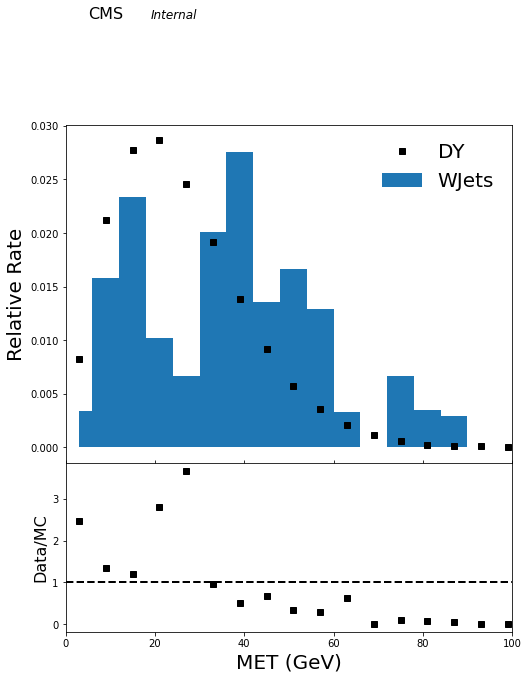

In [47]:
rebinWJetsMet=rebin(WJetsMetHist[0],6,WJetsMetHist[1])
normWJetsMet=normalize(rebinWJetsMet[0],rebinWJetsMet[1])
rebinDYJetsMet=rebin(DYJetsMetHist[0],6,DYJetsMetHist[1])
normDYJetsMet=normalize(rebinDYJetsMet[0],rebinDYJetsMet[1])
bins=rebinWJetsMet[1]
databins=rebinDYJetsMet[1]
plot(normWJetsMet,bins,dataHist=normDYJetsMet,dataBins=databins,title=None,figName='w_dyjets_met.pdf',xlabel='MET (GeV)',ylabel='Relative Rate',cmsX=5,mclab="WJets",datalab="DY",cmsY=0.04,cmsoff=14,xlim=[0,100])

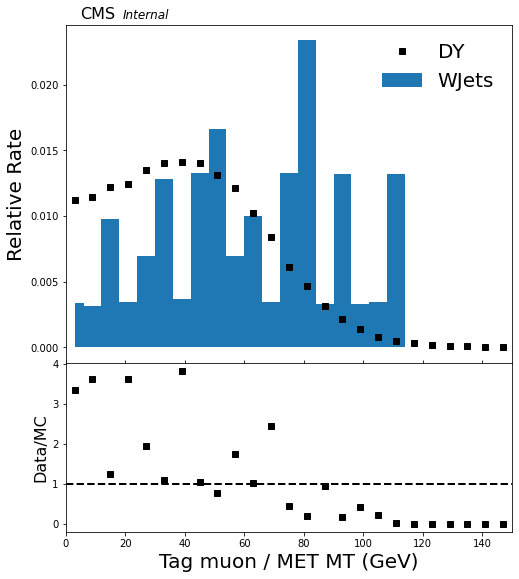

In [48]:
rebinWJetsMT=rebin(WJetsMTHist[0],6,WJetsMTHist[1])
normWJetsMT=normalize(rebinWJetsMT[0],rebinWJetsMT[1])
rebinDYJetsMT=rebin(DYJetsMTHist[0],6,DYJetsMTHist[1])
normDYJetsMT=normalize(rebinDYJetsMT[0],rebinDYJetsMT[1])
bins=rebinWJetsMT[1]
databins=rebinDYJetsMT[1]
plot(normWJetsMT,bins,dataHist=normDYJetsMT,dataBins=databins,title=None,figName='w_dyjets_mt.pdf',xlabel='Tag muon / MET MT (GeV)',ylabel='Relative Rate',cmsX=5,cmsY=0.025,xlim=[0,150],mclab="WJets",datalab="DY",cmsoff=14)

In [49]:
offPeakFile=uproot.open(str(inDir)+"/CRReReco_offPeak.root")
offPeakMEThist=offPeakFile["demo"]["passSig"]["totalMET"].to_numpy()
offPeakMThist=offPeakFile["demo"]["passSig"]["muMetMT"].to_numpy()
map0p2File=uproot.open(str(inDir)+"/ZmmDBrem_0p2.root")
map0p2hist=map0p2File["demo"]["allEvents"]["totalMET"].to_numpy()
map0p2MThist=map0p2File["demo"]["totalDisappear"]["muMetMT"].to_numpy()
map1p0File=uproot.open(str(inDir)+"/ZmmDBrem_1p0.root")
map1p0hist=map1p0File["demo"]["allEvents"]["totalMET"].to_numpy()
map1p0MThist=map1p0File["demo"]["totalDisappear"]["muMetMT"].to_numpy()


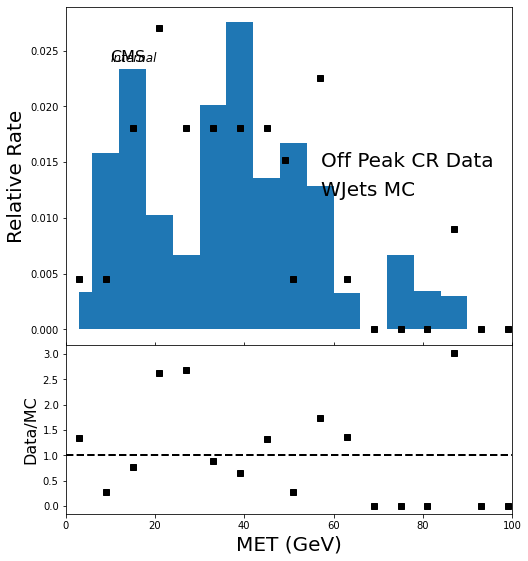

In [50]:
rebinOffPeakMT=rebin(offPeakMThist[0],6,offPeakMThist[1])
rebinOffPeakMET=rebin(offPeakMEThist[0],6,offPeakMEThist[1])
normOffPeakMT=normalize(rebinOffPeakMT[0],rebinOffPeakMT[1])
normOffPeakMET=normalize(rebinOffPeakMET[0],rebinOffPeakMET[1])
bins=rebinWJetsMet[1]
databins=rebinOffPeakMET[1]
plot(normWJetsMet,bins,dataHist=normOffPeakMET,dataBins=databins,title=None,figName='w_offpeak_met.pdf',xlabel='MET (GeV)',ylabel='Relative Rate',cmsX=10,cmsY=0.024,mclab="WJets MC",datalab="Off Peak CR Data",xlim=[0,100])

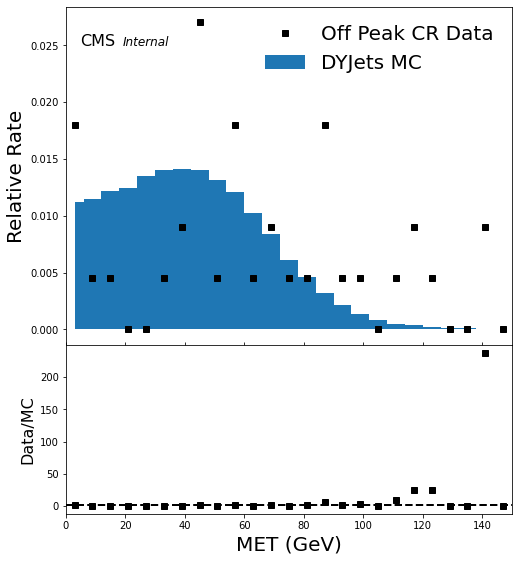

In [51]:
bins=rebinDYJetsMT[1]
databins=rebinOffPeakMT[1]
plot(normDYJetsMT,bins,dataHist=normOffPeakMT,dataBins=databins,title=None,figName='dy_offpeak_mt.pdf',xlabel='MET (GeV)',ylabel='Relative Rate',cmsX=5,cmsY=0.025,cmsoff=14,mclab="DYJets MC",datalab="Off Peak CR Data",xlim=[0,150])

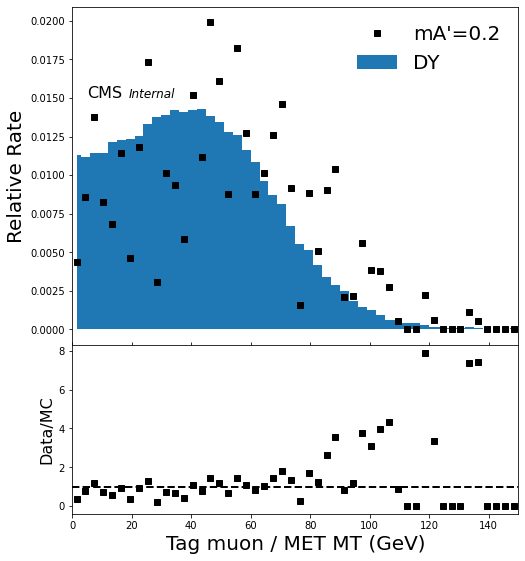

In [52]:
rebinMap0p2MT=rebin(map0p2MThist[0],3,map0p2MThist[1])
normMap0p2MT=normalize(rebinMap0p2MT[0],rebinMap0p2MT[1])
rebinDYJetsMT=rebin(DYJetsMTHist[0],3,DYJetsMTHist[1])
normDYJetsMT=normalize(rebinDYJetsMT[0],rebinDYJetsMT[1])
bins=rebinDYJetsMT[1]
databins=rebinMap0p2MT[1]
plot(normDYJetsMT,bins,dataHist=normMap0p2MT,dataBins=databins,title=None,figName='map0p2_dyjets_mt.pdf',xlabel='Tag muon / MET MT (GeV)',ylabel='Relative Rate',cmsX=5,cmsY=0.015,xlim=[0,150],mclab="DY",datalab="mA'=0.2",cmsoff=14)

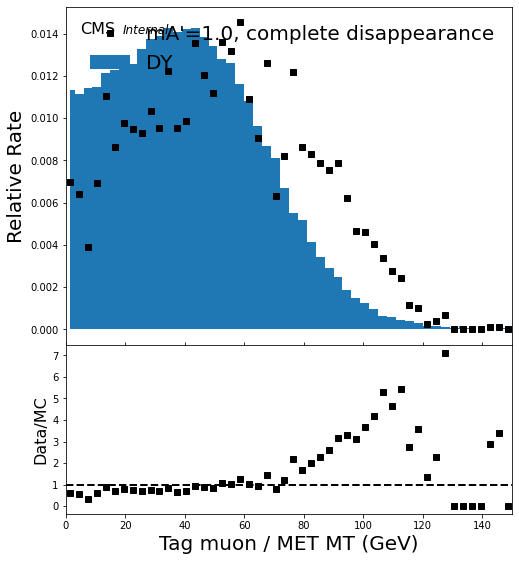

In [53]:
rebinMap1p0MT=rebin(map1p0MThist[0],3,map1p0MThist[1])
normMap1p0MT=normalize(rebinMap1p0MT[0],rebinMap1p0MT[1])
rebinDYJetsMT=rebin(DYJetsMTHist[0],3,DYJetsMTHist[1])
normDYJetsMT=normalize(rebinDYJetsMT[0],rebinDYJetsMT[1])
bins=rebinDYJetsMT[1]
databins=rebinMap1p0MT[1]
plot(normDYJetsMT,bins,dataHist=normMap1p0MT,dataBins=databins,title=None,figName='map1p0_dyjets_mt.pdf',xlabel='Tag muon / MET MT (GeV)',ylabel='Relative Rate',cmsX=5,cmsY=0.014,xlim=[0,150],mclab="DY",datalab="mA'=1.0, complete disappearance",cmsoff=14)

In [54]:
sum(map1p0MThist[0])

0.0770185078290524

In [55]:
count=0
p2count=0
offPeakCount=0
for bin in range(80):
    count=count+map1p0MThist[0][bin]
    p2count=p2count+map0p2MThist[0][bin]
    offPeakCount=offPeakCount+offPeakMThist[0][bin]
print(count)

0.06195414051762782


In [56]:
print(1-count/sum(map1p0MThist[0]))
print(1-p2count/sum(map0p2MThist[0]))
print(1-offPeakCount/sum((offPeakMThist[0])))

0.195594120634756
0.15852872813362384
0.32432432432432434


In [57]:
allFeatures = ["pt","eta","phi","staDR","staPhi","staE","staChi","cscDR","HEDepth_0","HEDepth_1","HEDepth_2","HEDepth_3","HEDepth_4","HEDepth_5","probeCharge","standaloneDEoverE","cscDRbyStation_0","cscDRbyStation_1","cscDRbyStation_2","cscDRbyStation_3","EventWeight","cellEdgeDeta","cellEdgeDphi"]
sigEvents=uproot.open(str(inDir)+"/ZmmDBrem_0p2.root:demo/partialDisappear/sigVariables")
sigArray = sigEvents.arrays(allFeatures,library="pd")
sigLowE = sigArray[sigArray['pt']<40]
sigHighE = sigArray[sigArray['pt']>40]
sigLowE["EventWeight"]=4000*sigLowE["EventWeight"]
sigHighE["EventWeight"]=4000*sigHighE["EventWeight"]

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  import sys


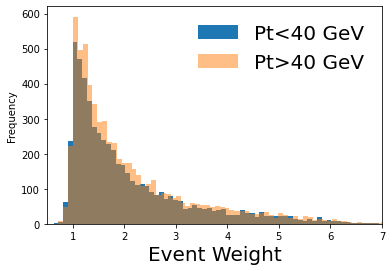

In [63]:
sigLowE["EventWeight"].plot.hist(bins=200,label='Pt<40 GeV')
sigHighE["EventWeight"].plot.hist(bins=200,alpha=0.5,label='Pt>40 GeV')
plt.xlim([0.5,7])
plt.xlabel('Event Weight',fontsize=20)
plt.legend(frameon=False,fontsize=20)